# GRAZPEDWRI-DX · Analiza slikovnih datoteka

Ovaj notebook analizira fizičke slike i njihove tehničke karakteristike. Metapodaci, pacijenti i klase obrađeni su u `01_dataset_eda.ipynb`, a geometrija i lokalni kontrast preloma u `03_fracture_eda.ipynb`. Numerička analiza obuhvata ceo dostupni skup; mali reproduktivan izbor koristi se samo za galerije. Originalne datoteke se ne menjaju.

## 0. Inicijalizacija

Koristimo projektne funkcije za učitavanje, merenje i prikaz. Putanje, seed i uključivanje keša određeni su zajedničkom konfiguracijom projekta.

In [33]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

from wrist_fracture.data.eda_settings import (
    DATASET, SEED, USE_CACHE, analytical_images, load_inputs, project_root,
    stratified_examples,
)
from wrist_fracture.data.image_eda import measure_images
from wrist_fracture.visualization.image_eda import show_gallery_pages

root = project_root()
cache_dir = root / 'results/cache/image_eda' if USE_CACHE else None
selection_dir = root / 'results/eda_review'
sns.set_theme(style='whitegrid', palette='deep', rc={
    'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.precision', 4)

statistic_labels = {
    'count': 'Broj izmerenih slika', 'mean': 'Srednja vrednost',
    'std': 'Standardna devijacija', 'min': 'Minimum', 'max': 'Maksimum',
}

def plot(fig):
    fig.tight_layout()
    plt.show()
    plt.close(fig)

## 1. Učitavanje i dostupnost slika

CSV i anotacije učitavamo jednom radi povezivanja identifikatora i kasnijih grupnih poređenja. ZIP direktorijumi daju inventar fizičkih slika bez raspakivanja. Provera je ograničena na dostupnost i jednoznačnost slikovnih identifikatora.

In [34]:
_, csv_path, annotation_path, metadata, audit, index, index_issues = load_inputs()
images = analytical_images(metadata, audit, index)
expected = set(metadata.filestem.dropna())
indexed = set(index.filestem)
annotation_ids = set(audit.files.filestem)
archive_counts = index.groupby(index.source.map(lambda source: Path(source).name)).filestem.agg(
    **{'Fizičke slike': 'size', 'Jedinstveni identifikatori': 'nunique'})
archive_counts.index.name = 'Arhiva'
display(archive_counts)
display(pd.Series({
    'Jedinstveni slikovni identifikatori': len(indexed),
    'CSV bez slike': len(expected - indexed),
    'Slika bez CSV zapisa': len(indexed - expected),
    'Slika bez anotacionog identifikatora': len(indexed - annotation_ids),
    'Anotacioni identifikator bez slike': len(annotation_ids - indexed),
    'Slikovni redovi sa duplim identifikatorom': int(index.filestem.duplicated(keep=False).sum()),
    'CSV redovi sa duplim identifikatorom': int(metadata.filestem.duplicated(keep=False).sum()),
}, name='Broj').to_frame())
if not index_issues.empty:
    display(index_issues.rename(columns={'source': 'Izvor', 'issue': 'Problem'}))
assert index.source.nunique() == 4, 'Nisu dostupne sve četiri arhive.'
assert len(images) == len(index), 'Dvosmisleni slikovni identifikatori zahtevaju proveru pre merenja.'

,Fizičke slike,Jedinstveni identifikatori
Arhiva,,
images_part1.zip,5031,5031
images_part2.zip,5143,5143
images_part3.zip,4842,4842
images_part4.zip,5311,5311


,Broj
Jedinstveni slikovni identifikatori,20327
CSV bez slike,0
Slika bez CSV zapisa,0
Slika bez anotacionog identifikatora,0
Anotacioni identifikator bez slike,0
Slikovni redovi sa duplim identifikatorom,0
CSV redovi sa duplim identifikatorom,0


### Zaključak

<!-- Zaključak će biti naknadno dopunjen. -->

## 2. Dekodiranje slika

Merenje prolazi kroz sve indeksirane slike (`limit=None`), po jednu sliku u memoriji. Postojeći keš proverava izvore, implementaciju, verzije biblioteka i integritet završenih serija; prekinuta obrada nastavlja se od nedostajućih ili nevalidnih serija. Problemi dekodiranja i nedostajuće metrike evidentiraju se odvojeno.

In [35]:
metrics, problems, state = measure_images(
    images, limit=None, seed=SEED, hashes=False,
    cache_dir=cache_dir, context={'dataset': DATASET})
measured = images.merge(metrics.drop(columns='filestem'), on='image_key', validate='one_to_one')
measured['megapixels'] = measured.width_px * measured.height_px / 1e6
display(pd.Series({
    'Pokušano dekodiranje': state['selected'],
    'Uspešno dekodirane slike': len(measured),
    'Neuspešno dekodirane slike': state['selected'] - len(measured),
    'Slike sa statistikama intenziteta': int(measured.get('pixel_mean', pd.Series(dtype=float)).count()),
    'Evidentirani problemi': len(problems),
}, name='Broj').to_frame())
if not problems.empty:
    display(problems.rename(columns={
        'image_key': 'Slikovni ključ', 'filestem': 'Identifikator slike', 'issue': 'Problem'}))
if measured.empty:
    raise RuntimeError('Nema dekodiranih slika za tehničku analizu.')
assert state['selected'] == len(index), 'Merenje ne obuhvata sve fizičke slike.'

INFO: Images completed: 1024/20327
INFO: Images completed: 2048/20327
INFO: Images completed: 3072/20327
INFO: Images completed: 4096/20327
INFO: Images completed: 5120/20327
INFO: Images completed: 6144/20327
INFO: Images completed: 7168/20327
INFO: Images completed: 8192/20327
INFO: Images completed: 9216/20327
INFO: Images completed: 10240/20327
INFO: Images completed: 11264/20327
INFO: Images completed: 12288/20327
INFO: Images completed: 13312/20327
INFO: Images completed: 14336/20327
INFO: Images completed: 15360/20327
INFO: Images completed: 16384/20327
INFO: Images completed: 17408/20327
INFO: Images completed: 18432/20327
INFO: Images completed: 19456/20327
INFO: Images completed: 20327/20327


,Broj
Pokušano dekodiranje,20327
Uspešno dekodirane slike,20327
Neuspešno dekodirane slike,0
Slike sa statistikama intenziteta,20327
Evidentirani problemi,0


## 3. Vizuelni pregled originalnih slika

Biramo po jedan primer iz svakog dostupnog preseka projekcije i proizvođača, uz primere iz tri uzrasna raspona. Ovo je namenski izbor raznovrsnih snimaka, bez procene učestalosti u populaciji. Ponavljanja objedinjavamo i čuvamo sve razloge izbora.

Galerija nema anotacione okvire. Granice P1–P99 računaju se posebno za svaku sliku isključivo radi prikaza sivih tonova; svi intenziteti u numeričkoj analizi ostaju izvorni. Zbog različitih granica prikaza svetlinu galerijskih panela ne treba neposredno porediti.

,Identifikator slike,Projekcija,Proizvođač,Uzrast (godine),Razlozi izbora
0,0133_0282914262_06_WRI-R1_M014,1,Agfa,14.2,projekcija=1 | proizvođač=Agfa
1,1986_0261107189_02_WRI-L1_M006,1,Siemens,6.4,projekcija=1 | proizvođač=Siemens
2,2980_0565365685_01_WRI-R2_F009,2,Agfa,9.0,projekcija=2 | proizvođač=Agfa
3,3732_0858458488_01_WRI-R2_F013,2,Siemens,13.0,projekcija=2 | proizvođač=Siemens
4,3195_1002525454_01_WRI-L3_M004,3,Siemens,4.0,projekcija=3 | proizvođač=Siemens
5,4378_0206807942_01_WRI-R2_M006,2,Siemens,6.0,uzrast (godine)=≤6
6,3994_0482391606_02_WRI-L1_M010,1,Siemens,10.9,uzrast (godine)=>6 do 12
7,4174_0221111536_03_WRI-L1_M017,1,Siemens,17.6,uzrast (godine)=>12


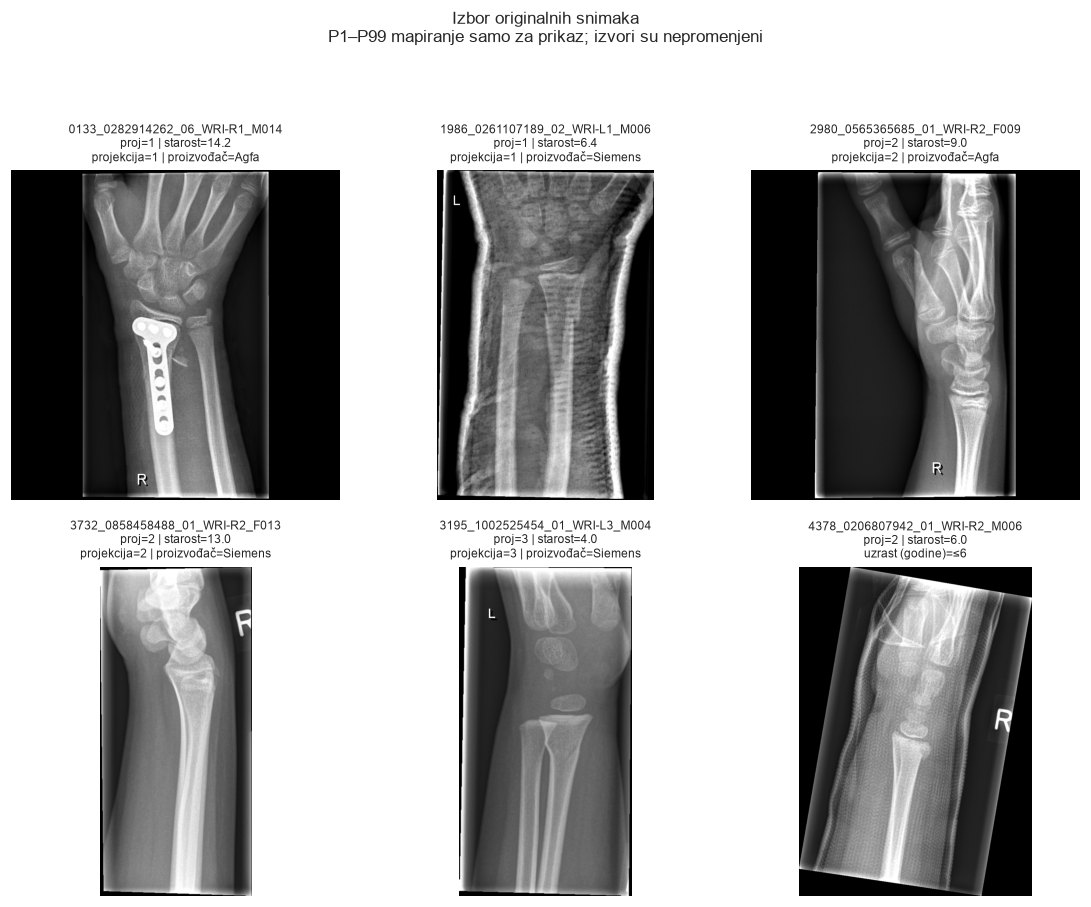

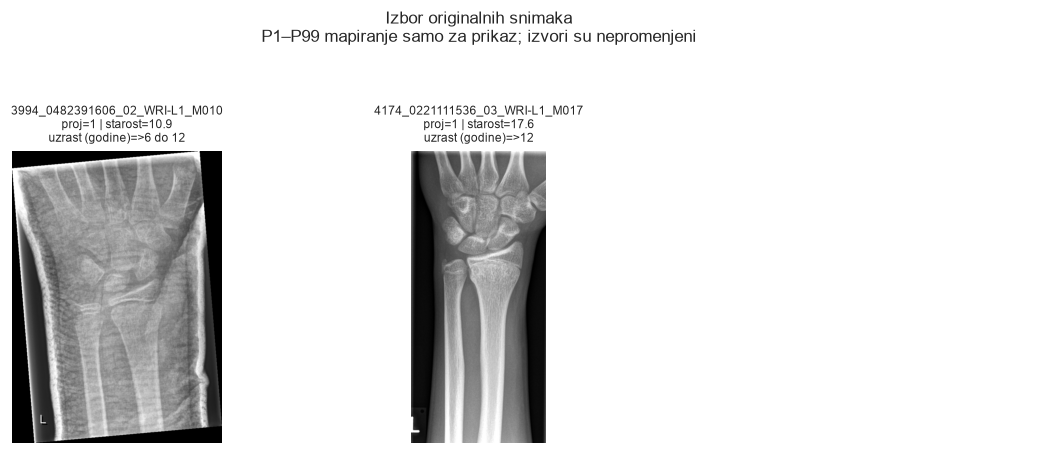

In [36]:
with_age = measured.assign(age_group=pd.cut(
    measured.age, [-np.inf, 6, 12, np.inf], labels=['≤6', '>6 do 12', '>12']))
representative_candidates = pd.concat([
    stratified_examples(measured, ['projection', 'device_manufacturer'], seed=SEED),
    stratified_examples(with_age, ['age_group'], seed=SEED),
], ignore_index=True)
representative_candidates['reason'] = (representative_candidates.reason
    .str.replace('projection=', 'projekcija=', regex=False)
    .str.replace('device_manufacturer=', 'proizvođač=', regex=False)
    .str.replace('age_group=', 'uzrast (godine)=', regex=False))
representative_reasons = representative_candidates.groupby('image_key', sort=False).reason.agg(
    lambda values: '; '.join(dict.fromkeys(values)))
representative = (representative_candidates.drop_duplicates('image_key').drop(columns='reason')
    .join(representative_reasons, on='image_key'))
display(representative[['filestem', 'projection', 'device_manufacturer', 'age', 'reason']].rename(columns={
    'filestem': 'Identifikator slike', 'projection': 'Projekcija',
    'device_manufacturer': 'Proizvođač', 'age': 'Uzrast (godine)', 'reason': 'Razlozi izbora'}))
show_gallery_pages(representative, audit.boxes, audit.classes, title='Izbor originalnih snimaka')

## 4. Format i dubina piksela

Dubina zapisa potiče iz zaglavlja datoteke; tip podataka i režim opisuju dekodirani raster. Jedinstvene kombinacije formata, dubine, tipa, kanala i frejmova prikazane su u jednoj tabeli.

In [37]:
format_columns = ['format', 'stored_bits', 'mode', 'dtype', 'channels', 'frames']
display(measured.groupby(format_columns, dropna=False).size().rename('Broj slika').reset_index().rename(columns={
    'format': 'Format', 'stored_bits': 'Dubina zapisa (bit/kanal)',
    'mode': 'Režim dekodiranja', 'dtype': 'Tip podataka',
    'channels': 'Broj kanala', 'frames': 'Broj frejmova'}))

,Format,Dubina zapisa (bit/kanal),Režim dekodiranja,Tip podataka,Broj kanala,Broj frejmova,Broj slika
0,PNG,16,I;16,uint16,1,1,20327


### Zaključak

Svih 20.327 analiziranih rendgenskih snimaka zapisano je u PNG formatu, sa dubinom zapisa od 16 bita po kanalu i tipom podataka `uint16`. Slike su jednokanalne (grayscale) i sadrže po jedan frejm.

Ujednačenost formata i načina zapisa pojednostavljuje kasniju predobradu slika. Međutim, zbog 16-bitnog zapisa, posebnu pažnju potrebno je posvetiti skaliranju intenziteta piksela i prilagođavanju ulaznih podataka zahtevima YOLO11 modela, uz očuvanje relevantnih vizuelnih informacija.

## 5. Dimenzije i rezolucija

Širina i visina opisuju izvorni raster, površina broj piksela u megapikselima, a odnos stranica oblik kadra. Ove mere su važne za kasniji izbor ulazne veličine i očuvanje geometrije. Ovde rezolucija označava broj piksela, a ne fizičku prostornu rezoluciju uređaja.

,Broj izmerenih slika,Srednja vrednost,Standardna devijacija,Minimum,25%,50%,75%,Maksimum
Širina (px),20327.0,562.7914,129.3166,212.0000,476.0000,549.0000,632.0000,1664.0000
Visina (px),20327.0,1009.1214,205.7125,324.0000,865.5000,999.0000,1144.0000,2328.0000
Površina (MP),20327.0,0.5797,0.2212,0.0826,0.4296,0.5445,0.6917,3.0950
Širina / visina,20327.0,0.5701,0.1307,0.2480,0.4799,0.5572,0.6430,1.6793


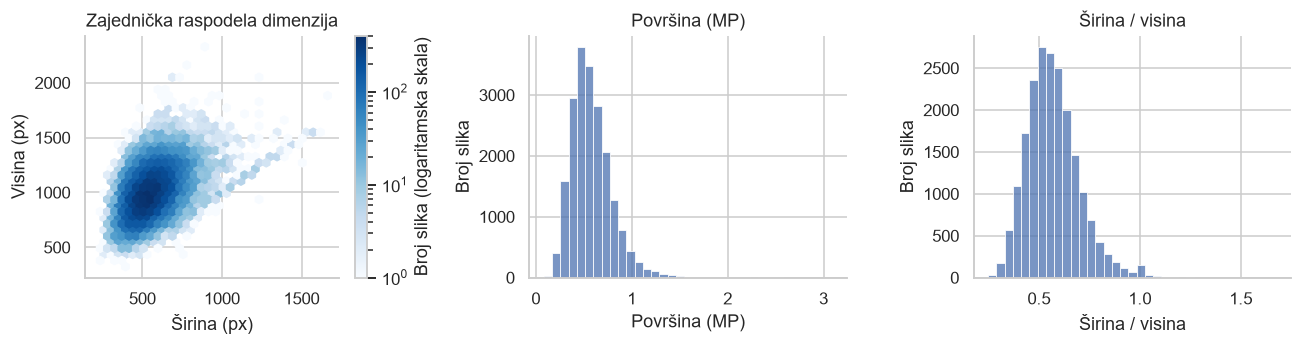

In [38]:
dim = ['width_px', 'height_px', 'megapixels', 'aspect_ratio']
display(measured[dim].describe().T.rename(index={
    'width_px': 'Širina (px)', 'height_px': 'Visina (px)',
    'megapixels': 'Površina (MP)', 'aspect_ratio': 'Širina / visina'
}).rename(columns=statistic_labels))
fig, axes = plt.subplots(1, 3, figsize=(12, 3.3))
density = axes[0].hexbin(measured.width_px, measured.height_px, gridsize=32, mincnt=1, bins='log', cmap='Blues')
fig.colorbar(density, ax=axes[0], label='Broj slika (logaritamska skala)')
axes[0].set(title='Zajednička raspodela dimenzija', xlabel='Širina (px)', ylabel='Visina (px)')
for ax, col, label in zip(axes[1:], dim[2:], ['Površina (MP)', 'Širina / visina']):
    sns.histplot(measured[col], bins=35, ax=ax)
    ax.set(title=label, xlabel=label, ylabel='Broj slika')
plot(fig)

### Zaključak

Analizom dimenzija svih 20.327 rendgenskih snimaka utvrđeno je da prosečna širina iznosi približno 563 piksela, a prosečna visina 1009 piksela. Dimenzije slika značajno variraju, pri čemu se rezolucija kreće od 0,083 do 3,095 megapiksela.

Raspodela rezolucije je asimetrična udesno, što ukazuje na manji broj snimaka sa izrazito visokom rezolucijom. Prosečan odnos širine i visine iznosi 0,57, što ukazuje na dominantnu vertikalnu orijentaciju snimaka.

Zbog različitih dimenzija i odnosa stranica, prilikom predobrade potrebno je primeniti promenu veličine slika uz očuvanje originalnih proporcija (letterbox), kako bi se izbegla geometrijska deformacija anatomskih struktura. Pri izboru ulazne rezolucije YOLO11 modela potrebno je voditi računa o očuvanju sitnih detalja značajnih za detekciju preloma.

## 6. Raspodela intenziteta piksela

Metrike su izračunate nad originalnim celobrojnim pikselima, bez konverzije u 8 bita. DN označava izvornu brojčanu vrednost intenziteta. Za svaku sliku već su izračunati minimum, maksimum, sredina, medijana, standardna devijacija i percentili P1, P5, P95 i P99.

Redovi tabele opisuju raspodele tih metrika **između slika**: svaka slika ima jednaku težinu bez obzira na broj piksela. Na primer, prosek srednjih vrednosti slika nije prosek svih piksela skupa, a medijana medijana nije medijana celokupne populacije piksela. Zajednička raspodela svih piksela ovde se ne procenjuje.

,Broj izmerenih slika,Srednja vrednost,Standardna devijacija,Minimum,25%,50%,75%,Maksimum
Minimum (DN),20327.0,0.0000,0.0000,0.0000,0.0000,0.0000,0.000,0.0000
Maksimum (DN),20327.0,65534.9994,0.0243,65534.0000,65535.0000,65535.0000,65535.000,65535.0000
Izmereni raspon (DN),20327.0,65534.9994,0.0243,65534.0000,65535.0000,65535.0000,65535.000,65535.0000
Srednja vrednost (DN),20327.0,19551.3386,4152.9972,2001.0151,16752.0169,19545.6264,22315.988,42146.5059
Medijana (DN),20327.0,19492.6095,5014.1328,0.0000,16593.5000,19644.0000,22671.000,45909.0000
Standardna devijacija (DN),20327.0,11376.6565,2174.3805,2306.8701,9821.7486,11215.0929,13006.667,20322.9894
P1 (DN),20327.0,734.3419,1855.7085,0.0000,0.0000,0.0000,0.000,19572.0000
P5 (DN),20327.0,2597.7236,3222.7986,0.0000,0.0000,0.0000,5184.500,26646.0000
P95 (DN),20327.0,38373.4972,6283.4061,6033.0000,33592.0000,38101.0000,43157.000,58606.0000
P99 (DN),20327.0,46847.7730,7235.3623,7890.0000,41225.0000,47483.0000,53028.500,65535.0000


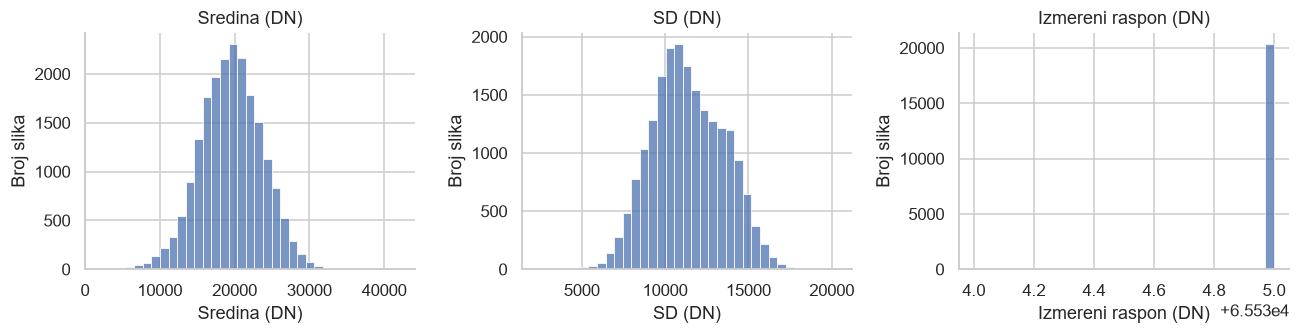

In [39]:
dn = ['pixel_min', 'pixel_max', 'observed_range', 'pixel_mean', 'pixel_median',
      'pixel_std', 'p01', 'p05', 'p95', 'p99']
display(measured.reindex(columns=dn).describe().T.rename(index=dict(zip(dn, [
    'Minimum (DN)', 'Maksimum (DN)', 'Izmereni raspon (DN)',
    'Srednja vrednost (DN)', 'Medijana (DN)', 'Standardna devijacija (DN)',
    'P1 (DN)', 'P5 (DN)', 'P95 (DN)', 'P99 (DN)'
]))).rename(columns=statistic_labels))
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, col, label in zip(axes, ['pixel_mean', 'pixel_std', 'observed_range'],
                          ['Sredina (DN)', 'SD (DN)', 'Izmereni raspon (DN)']):
    sns.histplot(measured.reindex(columns=[col])[col], bins=35, ax=ax)
    ax.set(title=label, xlabel=label, ylabel='Broj slika')
plot(fig)

### Zaključak

Analiza intenziteta piksela pokazuje da sve slike imaju minimalnu vrednost 0, dok maksimalne vrednosti iznose 65.534 ili 65.535. To ukazuje da gotovo sve slike dostižu granice raspoloživog 16-bitnog opsega.

Prosečna srednja vrednost intenziteta iznosi 19.551 DN, dok prosečna standardna devijacija iznosi 11.377 DN. Raspodele ovih statistika ukazuju na razlike u osvetljenosti i varijabilnosti intenziteta između snimaka, uprkos gotovo identičnom ukupnom rasponu vrednosti.

Dobijeni rezultati ukazuju da je linearno skaliranje na osnovu punog 16-bitnog opsega opravdana početna opcija za predobradu. Ipak, potrebno je razmotriti i metode zasnovane na percentilima, kako bi se što bolje očuvali kontrast i relevantni detalji rendgenskih snimaka.

## 7. Tehnički kvalitet slika

Osvetljenost je srednji intenzitet podeljen teorijskim maksimumom zapisa (65535 za unsigned 16-bitni zapis). Kontrast je P99−P1, takođe izražen kao udeo teorijskog raspona. To su izvedene mere prethodne sekcije, pa njihove histograme ne ponavljamo.

Udeli blizu donjeg i gornjeg kraja označavaju piksele sa vrednostima ≤1% i ≥99% teorijskog maksimuma, a ne krajeve opaženog raspona pojedinačne slike. Varijansa diskretnog Laplasijana računa se na rasteru podeljenom teorijskim maksimumom, bez rubnih piksela. Zavisi od rezolucije, šuma i sadržaja slike. Ove metrike služe tehničkom pregledu i nisu pouzdana procena dijagnostičkog kvaliteta.

,Broj izmerenih slika,Srednja vrednost,Standardna devijacija,Minimum,25%,50%,75%,Maksimum
Osvetljenost (udeo raspona),20327.0,0.2983,0.0634,3.0534e-02,2.5562e-01,2.9825e-01,0.3405,0.6431
Kontrast P99−P1 (udeo raspona),20327.0,0.7036,0.1133,1.2039e-01,6.1831e-01,7.1374e-01,0.7991,1.0000
Pikseli blizu nule (udeo),20327.0,0.0788,0.0873,2.0529e-06,1.9210e-02,5.3293e-02,0.1076,0.7340
Pikseli blizu maksimuma (udeo),20327.0,0.0002,0.0003,4.1250e-07,1.3943e-05,4.6953e-05,0.0003,0.0113
Varijansa Laplasijana (normalizovani raster),20327.0,0.0021,0.0010,3.6903e-04,1.4583e-03,1.8825e-03,0.0024,0.0137


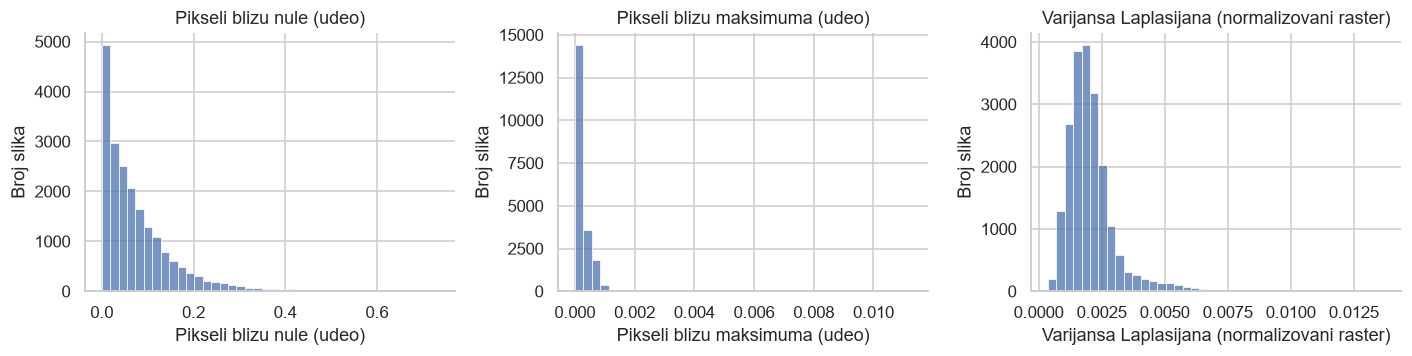

In [40]:
quality_labels = {
    'mean_fullscale': 'Osvetljenost (udeo raspona)',
    'contrast_fullscale': 'Kontrast P99−P1 (udeo raspona)',
    'near_zero_fraction': 'Pikseli blizu nule (udeo)',
    'near_ceiling_fraction': 'Pikseli blizu maksimuma (udeo)',
    'laplacian_variance': 'Varijansa Laplasijana (normalizovani raster)',
}
q = measured.reindex(columns=quality_labels)
display(q.describe().T.rename(index=quality_labels, columns=statistic_labels))
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, metric in zip(axes, ['near_zero_fraction', 'near_ceiling_fraction', 'laplacian_variance']):
    sns.histplot(q[metric], bins=40, ax=ax)
    ax.set(title=quality_labels[metric], xlabel=quality_labels[metric], ylabel='Broj slika')
plot(fig)

### Zaključak

Prosečna normalizovana osvetljenost rendgenskih snimaka iznosi 0,2983, dok prosečan kontrast, izražen razlikom između 99. i 1. percentila intenziteta, iznosi 0,7036.

Prosečan udeo piksela sa intenzitetom blizu nule iznosi 7,88%, dok je udeo piksela blizu maksimalnog intenziteta svega 0,02%. Kod pojedinih snimaka udeo veoma tamnih piksela dostiže 73,4%, što može biti posledica velike zastupljenosti tamne pozadine.

Raspodela varijanse Laplasijana ukazuje na razlike u oštrini između snimaka. Međutim, niske vrednosti ove metrike ne moraju nužno predstavljati zamućene ili nekvalitetne snimke.

Dobijeni rezultati ukazuju na heterogenost tehničkih karakteristika slika. Potrebno je vizuelno pregledati snimke sa ekstremnim vrednostima pre donošenja odluka o njihovoj predobradi ili eventualnom isključivanju iz skupa podataka.

## 8. Poređenje karakteristika slika po grupama

Po projekciji i proizvođaču upoređujemo površinu rastera, srednji intenzitet, kontrast i približnu oštrinu. Tabele daju veličinu grupe, broj izmerenih vrednosti i medijanu svake metrike. Broj slika naveden je i uz kategorije grafikona, jer su grupe nejednake. Kodovi projekcija ostaju izvorni.

Poređenja su deskriptivna: slike istog pacijenta nisu nezavisni uzorci, a razlike mogu odražavati sastav grupa i uslove snimanja. Iz ovih prikaza ne izvodimo kauzalne zaključke.

,Broj slika,Površina (MP) · n,Srednji intenzitet (DN) · n,Kontrast (udeo raspona) · n,Varijansa Laplasijana · n,Površina (MP) · medijana,Srednji intenzitet (DN) · medijana,Kontrast (udeo raspona) · medijana,Varijansa Laplasijana · medijana
Projekcija,,,,,,,,,
1,10086,10086,10086,10086,10086,0.5913,19597.4667,0.6840,0.0020
2,10148,10148,10148,10148,10148,0.5017,19516.3731,0.7588,0.0018
3,93,93,93,93,93,0.4943,17310.8395,0.6970,0.0019


,Broj slika,Površina (MP) · n,Srednji intenzitet (DN) · n,Kontrast (udeo raspona) · n,Varijansa Laplasijana · n,Površina (MP) · medijana,Srednji intenzitet (DN) · medijana,Kontrast (udeo raspona) · medijana,Varijansa Laplasijana · medijana
Proizvođač,,,,,,,,,
Agfa,112,112,112,112,112,1.1102,8929.5161,0.6648,0.0022
Siemens,20215,20215,20215,20215,20215,0.5433,19571.3530,0.7143,0.0019


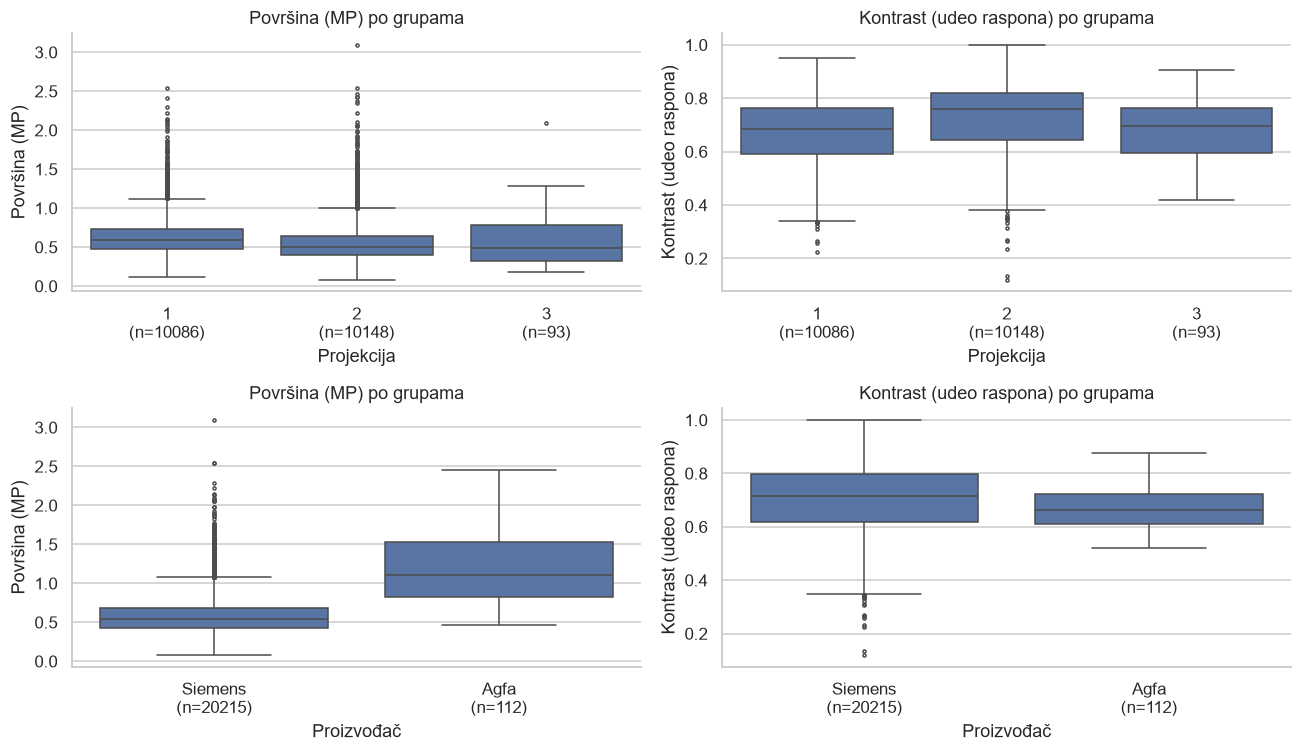

In [41]:
feature_labels = {
    'megapixels': 'Površina (MP)', 'pixel_mean': 'Srednji intenzitet (DN)',
    'contrast_fullscale': 'Kontrast (udeo raspona)',
    'laplacian_variance': 'Varijansa Laplasijana',
}
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for i, (key, group_label) in enumerate([
    ('projection', 'Projekcija'), ('device_manufacturer', 'Proizvođač')]):
    frame = measured[[key, *feature_labels]].copy()
    frame[key] = frame[key].astype('string').fillna('nedostaje')
    grouped = frame.groupby(key, sort=True)
    group_sizes = grouped.size()
    table = pd.concat([
        group_sizes.rename('Broj slika'),
        grouped[list(feature_labels)].count().rename(columns=feature_labels).add_suffix(' · n'),
        grouped[list(feature_labels)].median().rename(columns=feature_labels).add_suffix(' · medijana'),
    ], axis=1)
    table.index.name = group_label
    display(table)
    frame['group_display'] = frame[key].map(
        {value: f'{value}\n(n={count})' for value, count in group_sizes.items()})
    for j, metric in enumerate(['megapixels', 'contrast_fullscale']):
        sns.boxplot(data=frame, x='group_display', y=metric, ax=axes[i, j], fliersize=2)
        axes[i, j].set(title=f'{feature_labels[metric]} po grupama',
                       xlabel=group_label, ylabel=feature_labels[metric])
plot(fig)

### Zaključak

Poređenjem tehničkih karakteristika snimaka prema projekciji uočeno je da snimci projekcije 1 imaju najveću medijalnu rezoluciju (0,591 MP), dok snimci projekcije 2 imaju najveću medijalnu vrednost kontrasta (0,759).

Razlike su izraženije pri poređenju proizvođača uređaja. Snimci proizvođača Agfa imaju približno dvostruko veću medijalnu rezoluciju u odnosu na snimke proizvođača Siemens, ali niži medijalni intenzitet piksela i nešto niži kontrast.

Prilikom interpretacije rezultata potrebno je uzeti u obzir značajnu neuravnoteženost grupa, naročito prema proizvođaču uređaja i zastupljenosti projekcije 3.

Uočene razlike ukazuju na heterogenost tehničkih karakteristika snimaka, što je potrebno uzeti u obzir prilikom predobrade podataka i kasnije evaluacije generalizacije modela.

## 9. Ekstremne vrednosti i tehničke anomalije

Deterministički biramo po jedan minimum i maksimum širine, visine, površine, odnosa stranica, srednjeg intenziteta, kontrasta i varijanse Laplasijana. Pri izjednačenim vrednostima redosled određuje slikovni ključ. To je mali izbor krajeva raspodela za ručni pregled, bez formalnog praga neispravnosti. Sve razloge izbora iste slike objedinjavamo; svaki snimak se u ovoj galeriji prikazuje jednom. Ekstremna vrednost sama po sebi nije razlog za uklanjanje slike.

,Identifikator slike,Razlozi izbora
0,4588_1034162125_01_WRI-L2_F000,minimum: širina (px) (212)
1,5391_0667332742_01_WRI-L2_M014,maksimum: širina (px) (1664); maksimum: površi...
2,2822_0516653608_01_WRI-R1_M000,minimum: visina (px) (324)
3,3758_0699698609_02_WRI-R2_M015,maksimum: visina (px) (2328)
4,1387_1012595124_01_WRI-L2_F001,minimum: površina (MP) (0.08263)
6,2796_0758211815_01_WRI-R2_F008,minimum: širina / visina (0.248)
7,1296_0590400053_01_WRI-L1_F005,maksimum: širina / visina (1.679)
8,1110_1201775970_03_WRI-L2_M008,minimum: srednji intenzitet (DN) (2001)
9,0818_0571828119_04_WRI-R1_M013,maksimum: srednji intenzitet (DN) (4.215e+04)
10,2964_0926436692_02_WRI-L2_F012,minimum: kontrast (udeo raspona) (0.1204); min...


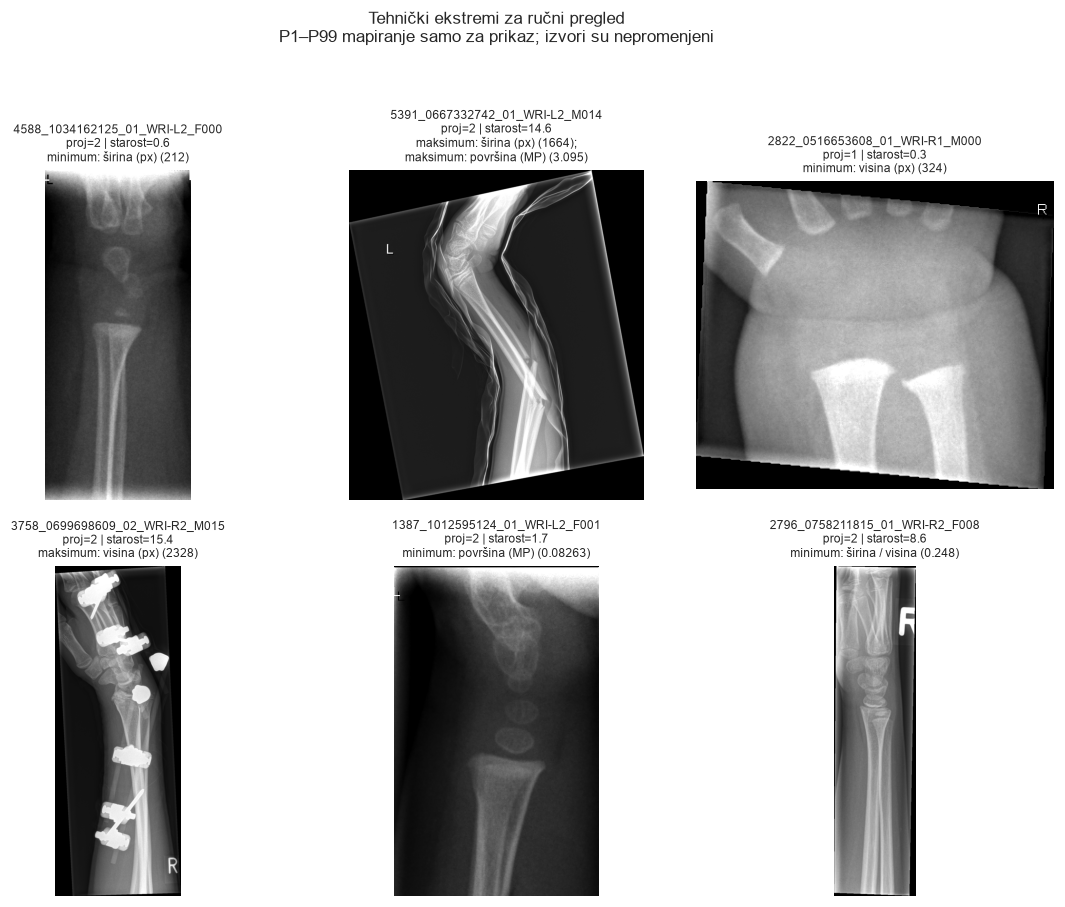

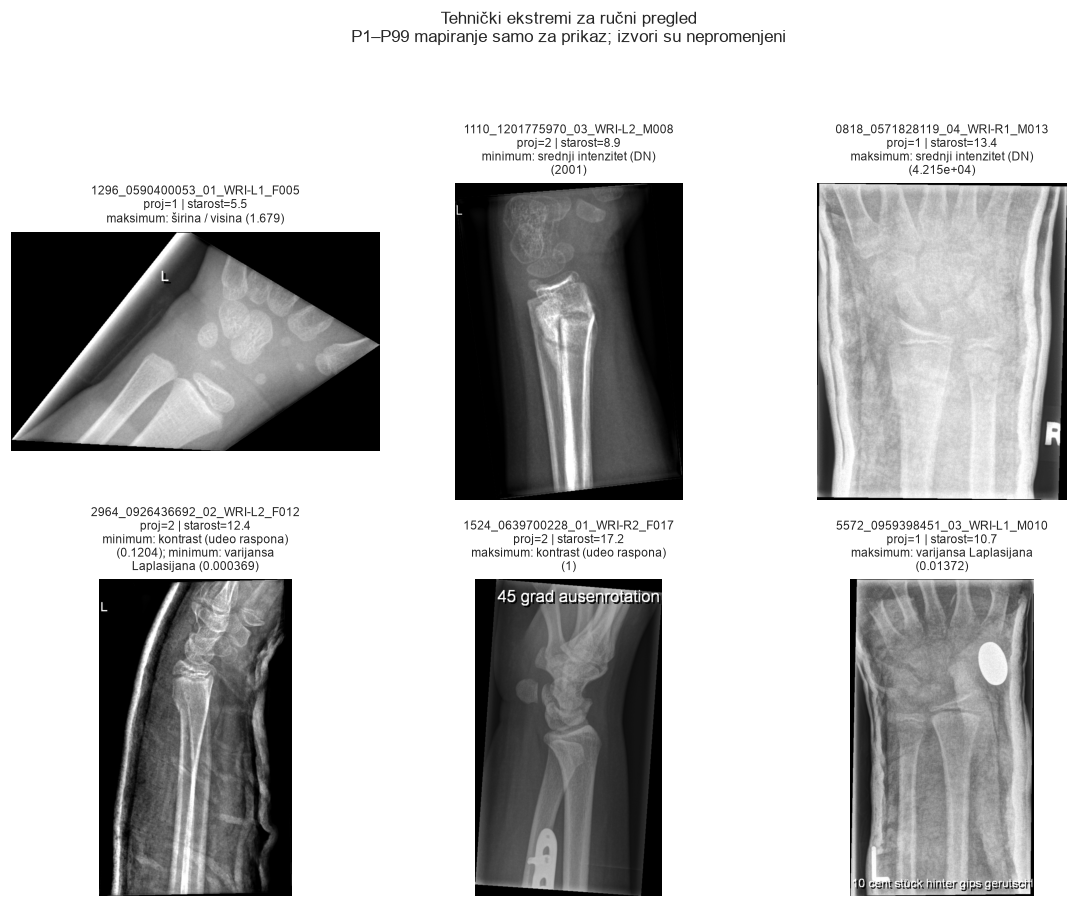

In [42]:
edge_parts = []
extreme_labels = {
    'width_px': 'širina (px)', 'height_px': 'visina (px)',
    'megapixels': 'površina (MP)', 'aspect_ratio': 'širina / visina',
    'pixel_mean': 'srednji intenzitet (DN)',
    'contrast_fullscale': 'kontrast (udeo raspona)',
    'laplacian_variance': 'varijansa Laplasijana',
}
for metric, label in extreme_labels.items():
    ordered = measured.dropna(subset=[metric]).sort_values([metric, 'image_key'])
    if not ordered.empty:
        for side, part in [('minimum', ordered.head(1)), ('maksimum', ordered.tail(1))]:
            edge_parts.append(part.assign(reason=f'{side}: {label} ({part[metric].iloc[0]:.4g})'))
technical_candidates = pd.concat(edge_parts, ignore_index=True)
technical_reasons = technical_candidates.groupby('image_key', sort=False).reason.agg(
    lambda values: '; '.join(dict.fromkeys(values)))
technical = (technical_candidates.drop_duplicates('image_key').drop(columns='reason')
    .join(technical_reasons, on='image_key'))
display(technical[['filestem', 'reason']].rename(columns={
    'filestem': 'Identifikator slike', 'reason': 'Razlozi izbora'}))
show_gallery_pages(technical, audit.boxes, audit.classes, title='Tehnički ekstremi za ručni pregled')

In [43]:
# Evidencija oba galerijska izbora; izvorne datoteke ostaju nepromenjene.
selection = pd.concat([
    representative.assign(izbor='stratifikovan'), technical.assign(izbor='ciljan')])
selection_dir.mkdir(parents=True, exist_ok=True)
selection.assign(seed=SEED, potpis=state['signature'], skup=DATASET)[
    ['filestem', 'member', 'izbor', 'reason', 'seed', 'potpis', 'skup']
].to_csv(selection_dir / 'image_gallery_selection.csv', index=False, encoding='utf-8-sig')

### Zaključak

Vizuelnim pregledom snimaka sa ekstremnim vrednostima uočene su razlike u dimenzijama, orijentaciji, osvetljenosti, kontrastu i oštrini. Na pojedinim snimcima prisutni su metalni elementi, imobilizacija, tekstualne oznake i izražene tamne površine.

Ekstremne vrednosti tehničkih metrika ne ukazuju nužno na neispravnost slikovnih podataka, već mogu biti posledica načina snimanja, pozicioniranja ekstremiteta i sadržaja same slike.

Zbog toga nije opravdano automatsko uklanjanje snimaka isključivo na osnovu analiziranih metrika. Ovakva raznovrsnost predstavlja dodatni izazov za detekciju preloma, ali može doprineti robusnosti modela u različitim uslovima snimanja.

## 10. Završni zaključak

Eksplorativna analiza slikovnih podataka obuhvatila je svih
20.327 rendgenskih snimaka iz skupa GRAZPEDWRI-DX.

Na osnovu sprovedene analize izdvojeni su sledeći ključni nalazi:

- **Dostupnost i integritet podataka:** Sve slike su uspešno
  dekodirane, bez evidentiranih grešaka pri učitavanju.

- **Format i dubina zapisa:** Sve slike su jednokanalne,
  zapisane u PNG formatu, sa dubinom od 16 bita i tipom
  podataka `uint16`.

- **Dimenzije i rezolucija:** Prisutne su značajne razlike
  u dimenzijama i rezoluciji snimaka, pri čemu dominira
  vertikalna orijentacija.

- **Intenzitet piksela:** Gotovo sve slike dostižu granice
  raspoloživog 16-bitnog opsega, ali se razlikuju prema
  raspodeli intenziteta i prosečnoj osvetljenosti.

- **Tehničke karakteristike:** Uočene su razlike u kontrastu,
  osvetljenosti i oštrini snimaka.

- **Projekcija i proizvođač uređaja:** Utvrđene su razlike
  u tehničkim karakteristikama između posmatranih grupa,
  uz izraženu neuravnoteženost njihove zastupljenosti.

- **Ekstremne vrednosti:** Vizuelni pregled pokazao je da
  ekstremne vrednosti tehničkih metrika nisu dovoljan
  kriterijum za automatsko isključivanje slika.

### Implikacije za dalji razvoj projekta

Na osnovu dobijenih rezultata, u fazi predobrade potrebno je:

- Ispitati odgovarajući način konverzije 16-bitnih slika
  u format pogodan za ulaz YOLO11 modela.
- Razmotriti linearno i percentilno skaliranje intenziteta.
- Očuvati originalne proporcije slika prilikom promene
  njihovih dimenzija primenom letterbox postupka.
- Odabrati ulaznu rezoluciju koja omogućava očuvanje
  sitnih detalja značajnih za detekciju preloma.
- Razmotriti uticaj različitih tehničkih karakteristika
  snimaka na generalizaciju modela.
- Izbegavati automatsko uklanjanje snimaka na osnovu
  ekstremnih vrednosti tehničkih metrika.

Konačne odluke o metodama predobrade biće donete nakon
analize karakteristika preloma i sprovođenja odgovarajućih
eksperimenata.